# BeeSafe AI — Phase 04: Baseline Model Training & Evaluation

**Purpose:** train and compare initial classifiers for the ApisTox binary toxicity label (`label`: 0 = dataset-defined non-toxic, 1 = dataset-defined toxic).

This notebook uses the frozen feature artifacts generated by Phase 03. It does **not** regenerate, edit, or overwrite the original dataset. The 10 records withheld by the conservative Phase 03 policy remain excluded from this first baseline.



## Cell 1 — Import libraries and set paths

In [1]:
from pathlib import Path
import os
import json
import hashlib
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    matthews_corrcoef,
    precision_score,
    recall_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay,
)
from sklearn.model_selection import StratifiedGroupKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import make_scorer
import joblib

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")

print("BeeSafe AI — Phase 04: Baseline Model Training & Evaluation")
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

BeeSafe AI — Phase 04: Baseline Model Training & Evaluation
NumPy: 2.5.2
Pandas: 3.0.5


## Cell 2 — Define project paths and verify Phase 03 outputs

In [2]:
DEFAULT_ROOT = Path(r"E:\CODE\Python\ALL Project\Machine Learning\BeeSafe AI")
PROJECT_ROOT = Path(os.environ.get("BEESAFE_PROJECT_ROOT", str(DEFAULT_ROOT)))

PHASE03_DIR = PROJECT_ROOT / "data" / "processed" / "phase03"
REPORT_DIR = PROJECT_ROOT / "reports" / "model_evaluation"
MODEL_DIR = PROJECT_ROOT / "models"
FIGURE_DIR = REPORT_DIR / "figures"

FEATURES_PATH = PHASE03_DIR / "03_baseline_features.npz"
METADATA_PATH = PHASE03_DIR / "03_baseline_metadata.csv"
MANIFEST_PATH = PROJECT_ROOT / "reports" / "feature_engineering" / "03_feature_manifest.json"

for folder in [REPORT_DIR, MODEL_DIR, FIGURE_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

required_paths = {
    "Phase 03 baseline features": FEATURES_PATH,
    "Phase 03 baseline metadata": METADATA_PATH,
    "Phase 03 feature manifest": MANIFEST_PATH,
}
missing_paths = [f"{label}: {path}" for label, path in required_paths.items() if not path.is_file()]
if missing_paths:
    raise FileNotFoundError(
        "Missing required Phase 03 output(s):\n- " + "\n- ".join(missing_paths)
        + "\nRun 03_data_preprocessing_and_feature_engineering.ipynb first."
    )

print("Project:", PROJECT_ROOT)
print("Features:", FEATURES_PATH)
print("Metadata:", METADATA_PATH)
print("Reports will be saved to:", REPORT_DIR)

Project: E:\CODE\Python\ALL Project\Machine Learning\BeeSafe AI
Features: E:\CODE\Python\ALL Project\Machine Learning\BeeSafe AI\data\processed\phase03\03_baseline_features.npz
Metadata: E:\CODE\Python\ALL Project\Machine Learning\BeeSafe AI\data\processed\phase03\03_baseline_metadata.csv
Reports will be saved to: E:\CODE\Python\ALL Project\Machine Learning\BeeSafe AI\reports\model_evaluation


## Cell 3 — Load feature matrices, metadata, and manifest

In [3]:
with np.load(FEATURES_PATH, allow_pickle=False) as saved:
    X_desc = saved["X_descriptors"].astype(np.float64, copy=True)
    X_morgan = saved["X_morgan"].copy()
    y = saved["y_binary"].astype(np.int64, copy=True)
    source_row_index = saved["source_row_index"].astype(np.int64, copy=True)
    descriptor_names = saved["descriptor_names"].astype(str).tolist()

metadata = pd.read_csv(METADATA_PATH)
with MANIFEST_PATH.open("r", encoding="utf-8") as f:
    phase03_manifest = json.load(f)

print("Descriptor matrix:", X_desc.shape)
print("Morgan fingerprint matrix:", X_morgan.shape)
print("Target vector:", y.shape)
print("Metadata:", metadata.shape)
print("Descriptor names:", descriptor_names)
print("Phase 03 baseline policy:", phase03_manifest.get("baseline_policy"))
display(metadata.head())

Descriptor matrix: (1025, 12)
Morgan fingerprint matrix: (1025, 2048)
Target vector: (1025,)
Metadata: (1025, 29)
Descriptor names: ['MolWt', 'MolLogP', 'TPSA', 'NumHDonors', 'NumHAcceptors', 'RingCount', 'HeavyAtomCount', 'NumRotatableBonds', 'NumAromaticRings', 'FractionCSP3', 'FormalCharge', 'NumHeteroatoms']
Phase 03 baseline policy: WITHHOLD_ALL_PHASE02_REVIEW_PRIORITY_NON_NONE


,source_row_index,name,CID,CAS,SMILES,source,year,toxicity_type,herbicide,fungicide,insecticide,other_agrochemical,label,ppdb_level,review_priority,phase02_issue_flags,pubchem_verification_status,smiles_valid,canonical_smiles,largest_fragment_smiles,murcko_scaffold,structure_group,structure_parse_status,descriptors_finite,fingerprint_nonzero_bits,fingerprint_valid,binary_label_valid,baseline_eligible,baseline_decision_reason
0,0,Ethanedioic acid,971,144-62-7,O=C(O)C(=O)O,ECOTOX,1832,Contact,0,0,0,0,0,0,NONE,NaN,NOT_FLAGGED_FOR_LOOKUP,True,O=C(O)C(=O)O,O=C(O)C(=O)O,NaN,ACYCLIC:O=C(O)C(=O)O,VALID,True,6,True,True,True,INCLUDED
1,1,Para-cymene,7463,99-87-6,Cc1ccc(C(C)C)cc1,BPDB,1833,Other,0,0,0,1,0,1,NONE,NaN,NOT_FLAGGED_FOR_LOOKUP,True,Cc1ccc(C(C)C)cc1,Cc1ccc(C(C)C)cc1,c1ccccc1,SCAFFOLD:c1ccccc1,VALID,True,15,True,True,True,INCLUDED
2,2,Kieselguhr,24261,61790-53-2,O=[Si]=O,ECOTOX,1833,Contact,0,0,0,0,0,0,NONE,NaN,NOT_FLAGGED_FOR_LOOKUP,True,O=[Si]=O,O=[Si]=O,NaN,ACYCLIC:O=[Si]=O,VALID,True,4,True,True,True,INCLUDED
3,3,Benzoic acid,243,65-85-0,O=C(O)c1ccccc1,ECOTOX,1833,Contact,1,1,1,0,0,1,NONE,NaN,NOT_FLAGGED_FOR_LOOKUP,True,O=C(O)c1ccccc1,O=C(O)c1ccccc1,c1ccccc1,SCAFFOLD:c1ccccc1,VALID,True,14,True,True,True,INCLUDED
4,4,Tetradifon (Ref: ENT 23737),8305,116-29-0,O=S(=O)(c1ccc(Cl)cc1)c1cc(Cl)c(Cl)cc1Cl,PPDB,1836,Oral,0,0,0,1,1,1,NONE,NaN,NOT_FLAGGED_FOR_LOOKUP,True,O=S(=O)(c1ccc(Cl)cc1)c1cc(Cl)c(Cl)cc1Cl,O=S(=O)(c1ccc(Cl)cc1)c1cc(Cl)c(Cl)cc1Cl,O=S(=O)(c1ccccc1)c1ccccc1,SCAFFOLD:O=S(=O)(c1ccccc1)c1ccccc1,VALID,True,24,True,True,True,INCLUDED


## Cell 4 — Integrity and leakage checks

In [4]:
required_metadata = {"source_row_index", "name", "CID", "CAS", "label", "structure_group", "review_priority"}
missing_metadata = required_metadata - set(metadata.columns)
if missing_metadata:
    raise ValueError(f"Metadata is missing required columns: {sorted(missing_metadata)}")

n = len(y)
if len(metadata) != n or len(source_row_index) != n or len(X_desc) != n or len(X_morgan) != n:
    raise ValueError("Feature arrays, target, and metadata do not have the same number of rows.")
if not np.array_equal(source_row_index, metadata["source_row_index"].to_numpy(dtype=np.int64)):
    raise ValueError("Source row order mismatch between feature arrays and metadata.")
if not np.array_equal(y, metadata["label"].to_numpy(dtype=np.int64)):
    raise ValueError("Target labels differ between NPZ and metadata.")
if set(np.unique(y)) != {0, 1}:
    raise ValueError(f"Expected binary target labels 0 and 1; found {np.unique(y)}")
if not np.isfinite(X_desc).all():
    raise ValueError("Descriptor matrix contains NaN or infinity; revisit Phase 03.")
if not np.isin(X_morgan, [0, 1]).all():
    raise ValueError("Morgan fingerprints are expected to contain only 0/1 values.")
if metadata["structure_group"].isna().any() or metadata["structure_group"].astype(str).str.strip().eq("").any():
    raise ValueError("Missing structure_group values; revisit Phase 03 before splitting.")
if not metadata["review_priority"].astype(str).eq("NONE").all():
    raise ValueError("Baseline metadata contains reviewed/flagged records; inspect Phase 03 policy.")
if len(np.unique(source_row_index)) != n:
    raise ValueError("Repeated source_row_index detected.")

class_counts = pd.Series(y).value_counts().sort_index()
class_summary = pd.DataFrame({
    "label": class_counts.index,
    "class_name": ["Non-toxic (dataset label 0)" if i == 0 else "Toxic (dataset label 1)" for i in class_counts.index],
    "records": class_counts.values,
    "percentage": (class_counts.values / n * 100).round(2),
})
print("All integrity checks passed.")
print("Samples:", n)
print("Descriptor features:", X_desc.shape[1])
print("Fingerprint bits:", X_morgan.shape[1])
print("Unique structure groups:", metadata["structure_group"].nunique())
display(class_summary)

All integrity checks passed.
Samples: 1025
Descriptor features: 12
Fingerprint bits: 2048
Unique structure groups: 566


,label,class_name,records,percentage
0,0,Non-toxic (dataset label 0),731,71.32
1,1,Toxic (dataset label 1),294,28.68


## Cell 5 — Create a structure-group-aware holdout split

In [5]:
# Use one fold of StratifiedGroupKFold as a reproducible ~20% holdout.
# The same structure_group is never allowed in both train and test.
X_all_desc = X_desc
X_all_fp = X_morgan
labels = y
groups = metadata["structure_group"].astype(str).to_numpy()

outer_splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
outer_splits = list(outer_splitter.split(X_all_desc, labels, groups=groups))
train_idx, test_idx = outer_splits[0]

X_desc_train, X_desc_test = X_all_desc[train_idx], X_all_desc[test_idx]
X_fp_train, X_fp_test = X_all_fp[train_idx], X_all_fp[test_idx]
y_train, y_test = labels[train_idx], labels[test_idx]
groups_train, groups_test = groups[train_idx], groups[test_idx]

train_group_set, test_group_set = set(groups_train), set(groups_test)
assert train_group_set.isdisjoint(test_group_set), "Structure group leakage detected!"
assert set(np.unique(y_train)) == {0, 1}, "Training split must contain both labels."
assert set(np.unique(y_test)) == {0, 1}, "Holdout split must contain both labels."

split_summary = pd.DataFrame([
    {"split": "train", "records": len(train_idx), "positive_toxic": int(y_train.sum()),
     "positive_percentage": round(y_train.mean() * 100, 2), "unique_groups": len(train_group_set)},
    {"split": "holdout_test", "records": len(test_idx), "positive_toxic": int(y_test.sum()),
     "positive_percentage": round(y_test.mean() * 100, 2), "unique_groups": len(test_group_set)},
])
print("Train/test structure-group overlap:", len(train_group_set & test_group_set))
print("Holdout fraction:", round(len(test_idx) / n, 3))
display(split_summary)

split_assignments = metadata[["source_row_index", "name", "CID", "label", "structure_group"]].copy()
split_assignments["split"] = "train"
split_assignments.loc[test_idx, "split"] = "holdout_test"
split_assignments.to_csv(REPORT_DIR / "04_split_assignments.csv", index=False, encoding="utf-8-sig")
print("Saved split assignments:", REPORT_DIR / "04_split_assignments.csv")

Train/test structure-group overlap: 0
Holdout fraction: 0.199


,split,records,positive_toxic,positive_percentage,unique_groups
0,train,821,236,28.75,534
1,holdout_test,204,58,28.43,32


Saved split assignments: E:\CODE\Python\ALL Project\Machine Learning\BeeSafe AI\reports\model_evaluation\04_split_assignments.csv


## Cell 6 — Define baseline models

In [6]:
# Scaling is performed inside a Pipeline, fitted separately on each training fold.
# Class weighting is used in several models as a baseline response to class imbalance.
models = {
    "Dummy prior baseline": {
        "features": "descriptors",
        "estimator": DummyClassifier(strategy="prior"),
    },
    "Logistic Regression — descriptors": {
        "features": "descriptors",
        "estimator": Pipeline([
            ("scaler", StandardScaler()),
            ("model", LogisticRegression(class_weight="balanced", max_iter=4000, random_state=RANDOM_STATE)),
        ]),
    },
    "RBF SVM — descriptors": {
        "features": "descriptors",
        "estimator": Pipeline([
            ("scaler", StandardScaler()),
            ("model", SVC(kernel="rbf", class_weight="balanced", probability=False, random_state=RANDOM_STATE)),
        ]),
    },
    "Random Forest — descriptors": {
        "features": "descriptors",
        "estimator": RandomForestClassifier(
            n_estimators=200, max_features="sqrt", min_samples_leaf=2,
            class_weight="balanced_subsample", random_state=RANDOM_STATE, n_jobs=-1,
        ),
    },
    "Extra Trees — descriptors": {
        "features": "descriptors",
        "estimator": ExtraTreesClassifier(
            n_estimators=200, max_features="sqrt", min_samples_leaf=2,
            class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1,
        ),
    },
    "Logistic Regression — Morgan": {
        "features": "morgan",
        "estimator": LogisticRegression(class_weight="balanced", max_iter=4000, random_state=RANDOM_STATE),
    },
    "Random Forest — Morgan": {
        "features": "morgan",
        "estimator": RandomForestClassifier(
            n_estimators=200, max_features="sqrt", min_samples_leaf=2,
            class_weight="balanced_subsample", random_state=RANDOM_STATE, n_jobs=-1,
        ),
    },
    "Extra Trees — Morgan": {
        "features": "morgan",
        "estimator": ExtraTreesClassifier(
            n_estimators=200, max_features="sqrt", min_samples_leaf=2,
            class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1,
        ),
    },
}

print(f"Defined {len(models)} baseline configurations.")
for name, spec in models.items():
    print(f"- {name} [{spec['features']}]")

Defined 8 baseline configurations.
- Dummy prior baseline [descriptors]
- Logistic Regression — descriptors [descriptors]
- RBF SVM — descriptors [descriptors]
- Random Forest — descriptors [descriptors]
- Extra Trees — descriptors [descriptors]
- Logistic Regression — Morgan [morgan]
- Random Forest — Morgan [morgan]
- Extra Trees — Morgan [morgan]


## Cell 7 — Run grouped cross-validation on the training split

In [7]:
# Model comparison uses training data only. The holdout set is not used to select hyperparameters.
inner_cv = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=RANDOM_STATE + 1)
scoring = {
    "roc_auc": "roc_auc",
    "average_precision": "average_precision",
    "balanced_accuracy": "balanced_accuracy",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": make_scorer(recall_score, zero_division=0),
    "f1": make_scorer(f1_score, zero_division=0),
    "mcc": make_scorer(matthews_corrcoef),
}

cv_rows = []
cv_raw_results = {}

for model_name, spec in models.items():
    feature_type = spec["features"]
    X_train_model = X_desc_train if feature_type == "descriptors" else X_fp_train
    print(f"Cross-validating: {model_name} ...", flush=True)
    result = cross_validate(
        clone(spec["estimator"]),
        X_train_model,
        y_train,
        cv=inner_cv,
        groups=groups_train,
        scoring=scoring,
        n_jobs=1,
        return_train_score=False,
        error_score="raise",
    )
    cv_raw_results[model_name] = result
    row = {"model": model_name, "features": feature_type}
    for metric in scoring:
        values = result[f"test_{metric}"]
        row[f"cv_{metric}_mean"] = float(np.mean(values))
        row[f"cv_{metric}_std"] = float(np.std(values, ddof=1))
    cv_rows.append(row)
    print(f"  mean PR-AUC={row['cv_average_precision_mean']:.3f}; mean ROC-AUC={row['cv_roc_auc_mean']:.3f}")

cv_results = pd.DataFrame(cv_rows).sort_values(
    "cv_average_precision_mean", ascending=False
).reset_index(drop=True)
cv_results.to_csv(REPORT_DIR / "04_grouped_cv_results.csv", index=False, encoding="utf-8-sig")
print("\nGrouped CV results (ranked by mean Average Precision / PR-AUC):")
display(cv_results.round(4))
print("Saved:", REPORT_DIR / "04_grouped_cv_results.csv")

Cross-validating: Dummy prior baseline ...
  mean PR-AUC=0.287; mean ROC-AUC=0.500
Cross-validating: Logistic Regression — descriptors ...
  mean PR-AUC=0.474; mean ROC-AUC=0.682
Cross-validating: RBF SVM — descriptors ...
  mean PR-AUC=0.540; mean ROC-AUC=0.689
Cross-validating: Random Forest — descriptors ...


D:\Anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
D:\Anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
D:\Anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
D:\Anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` 

  mean PR-AUC=0.588; mean ROC-AUC=0.724
Cross-validating: Extra Trees — descriptors ...
  mean PR-AUC=0.585; mean ROC-AUC=0.723
Cross-validating: Logistic Regression — Morgan ...
  mean PR-AUC=0.694; mean ROC-AUC=0.785
Cross-validating: Random Forest — Morgan ...
  mean PR-AUC=0.759; mean ROC-AUC=0.824
Cross-validating: Extra Trees — Morgan ...
  mean PR-AUC=0.753; mean ROC-AUC=0.818

Grouped CV results (ranked by mean Average Precision / PR-AUC):


,model,features,cv_roc_auc_mean,cv_roc_auc_std,cv_average_precision_mean,cv_average_precision_std,cv_balanced_accuracy_mean,cv_balanced_accuracy_std,cv_precision_mean,cv_precision_std,cv_recall_mean,cv_recall_std,cv_f1_mean,cv_f1_std,cv_mcc_mean,cv_mcc_std
0,Random Forest — Morgan,morgan,0.8237,0.0319,0.7593,0.0262,0.7469,0.0232,0.8314,0.0568,0.5384,0.0398,0.6528,0.0397,0.5743,0.0519
1,Extra Trees — Morgan,morgan,0.8177,0.0310,0.7533,0.0363,0.7570,0.0356,0.7808,0.0750,0.5808,0.0606,0.6648,0.0576,0.5677,0.0762
2,Logistic Regression — Morgan,morgan,0.7854,0.0347,0.6937,0.0228,0.7268,0.0104,0.6422,0.0130,0.5852,0.0312,0.6118,0.0139,0.4668,0.0121
3,Random Forest — descriptors,descriptors,0.7241,0.0489,0.5875,0.0820,0.6471,0.0501,0.6306,0.0497,0.3814,0.1107,0.4710,0.1016,0.3492,0.0917
4,Extra Trees — descriptors,descriptors,0.7233,0.0279,0.5846,0.0581,0.6589,0.0466,0.5829,0.0324,0.4444,0.1165,0.4993,0.0867,0.3467,0.0760
5,RBF SVM — descriptors,descriptors,0.6892,0.0149,0.5395,0.0597,0.6336,0.0235,0.4729,0.0332,0.4912,0.0825,0.4782,0.0411,0.2655,0.0418
6,Logistic Regression — descriptors,descriptors,0.6817,0.0459,0.4740,0.0508,0.6460,0.0314,0.4312,0.0210,0.6236,0.0838,0.5085,0.0369,0.2687,0.0546
7,Dummy prior baseline,descriptors,0.5000,0.0000,0.2874,0.0038,0.5000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000


Saved: E:\CODE\Python\ALL Project\Machine Learning\BeeSafe AI\reports\model_evaluation\04_grouped_cv_results.csv


## Cell 8 — Plot cross-validation model comparison

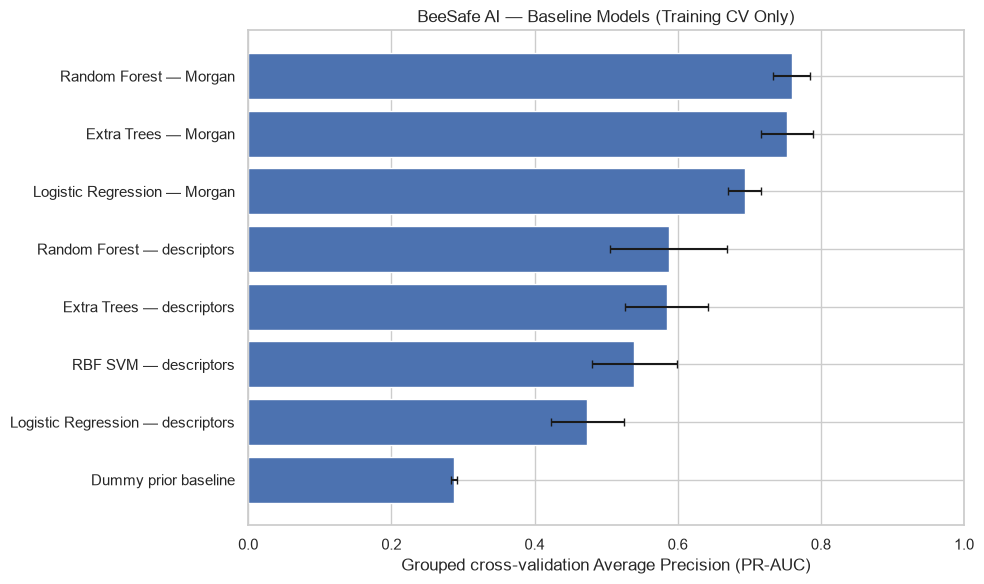

Primary selection metric: mean grouped-CV Average Precision.
This chart uses training folds only; the holdout set has not selected the model.


In [8]:
plot_cv = cv_results.sort_values("cv_average_precision_mean", ascending=True)
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(plot_cv["model"], plot_cv["cv_average_precision_mean"],
        xerr=plot_cv["cv_average_precision_std"], capsize=3)
ax.set_xlabel("Grouped cross-validation Average Precision (PR-AUC)")
ax.set_title("BeeSafe AI — Baseline Models (Training CV Only)")
ax.set_xlim(0, 1)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "04_grouped_cv_model_comparison.png", dpi=220, bbox_inches="tight")
plt.show()

print("Primary selection metric: mean grouped-CV Average Precision.")
print("This chart uses training folds only; the holdout set has not selected the model.")

## Cell 9 — Fit each baseline on training data and evaluate once on the holdout

In [9]:
def positive_class_score(estimator, X):
    """Return a continuous score for class 1, using probabilities or decision function."""
    if hasattr(estimator, "predict_proba"):
        probabilities = estimator.predict_proba(X)
        class_list = list(estimator.classes_)
        if 1 not in class_list:
            raise ValueError("Model has no positive class 1 in classes_.")
        return probabilities[:, class_list.index(1)]
    if hasattr(estimator, "decision_function"):
        scores = np.asarray(estimator.decision_function(X))
        if scores.ndim == 2:
            class_list = list(estimator.classes_)
            return scores[:, class_list.index(1)]
        return scores
    return estimator.predict(X).astype(float)

holdout_rows = []
fitted_models = {}
prediction_outputs = {}

for model_name, spec in models.items():
    feature_type = spec["features"]
    X_train_model = X_desc_train if feature_type == "descriptors" else X_fp_train
    X_test_model = X_desc_test if feature_type == "descriptors" else X_fp_test
    estimator = clone(spec["estimator"])
    print(f"Fitting on training split: {model_name} ...", flush=True)
    estimator.fit(X_train_model, y_train)
    y_pred = estimator.predict(X_test_model).astype(int)
    y_score = positive_class_score(estimator, X_test_model)

    metrics = {
        "model": model_name,
        "features": feature_type,
        "test_roc_auc": roc_auc_score(y_test, y_score),
        "test_average_precision": average_precision_score(y_test, y_score),
        "test_balanced_accuracy": balanced_accuracy_score(y_test, y_pred),
        "test_precision": precision_score(y_test, y_pred, zero_division=0),
        "test_recall": recall_score(y_test, y_pred, zero_division=0),
        "test_f1": f1_score(y_test, y_pred, zero_division=0),
        "test_mcc": matthews_corrcoef(y_test, y_pred),
    }
    if hasattr(estimator, "predict_proba"):
        from sklearn.metrics import brier_score_loss
        metrics["test_brier_score"] = brier_score_loss(y_test, y_score)
    else:
        metrics["test_brier_score"] = np.nan

    holdout_rows.append(metrics)
    fitted_models[model_name] = estimator
    prediction_outputs[model_name] = {"y_pred": y_pred, "y_score": y_score}

holdout_results = pd.DataFrame(holdout_rows).sort_values(
    "test_average_precision", ascending=False
).reset_index(drop=True)
holdout_results.to_csv(REPORT_DIR / "04_holdout_test_results.csv", index=False, encoding="utf-8-sig")
print("Holdout test results (diagnostic comparison; do not tune to this table):")
display(holdout_results.round(4))
print("Saved:", REPORT_DIR / "04_holdout_test_results.csv")

Fitting on training split: Dummy prior baseline ...
Fitting on training split: Logistic Regression — descriptors ...
Fitting on training split: RBF SVM — descriptors ...
Fitting on training split: Random Forest — descriptors ...


D:\Anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Fitting on training split: Extra Trees — descriptors ...
Fitting on training split: Logistic Regression — Morgan ...
Fitting on training split: Random Forest — Morgan ...
Fitting on training split: Extra Trees — Morgan ...
Holdout test results (diagnostic comparison; do not tune to this table):


,model,features,test_roc_auc,test_average_precision,test_balanced_accuracy,test_precision,test_recall,test_f1,test_mcc,test_brier_score
0,Logistic Regression — Morgan,morgan,0.9320,0.8824,0.8627,0.6753,0.8966,0.7704,0.6750,0.1141
1,Random Forest — Morgan,morgan,0.9295,0.8706,0.8605,0.8491,0.7759,0.8108,0.7417,0.1122
2,Extra Trees — Morgan,morgan,0.9237,0.8645,0.8520,0.7797,0.7931,0.7863,0.7005,0.1086
3,Logistic Regression — descriptors,descriptors,0.7898,0.7099,0.7080,0.4828,0.7241,0.5793,0.3794,0.2076
4,Random Forest — descriptors,descriptors,0.7671,0.6773,0.7037,0.7179,0.4828,0.5773,0.4674,0.1609
5,Extra Trees — descriptors,descriptors,0.7434,0.6703,0.7073,0.6667,0.5172,0.5825,0.4509,0.1751
6,RBF SVM — descriptors,descriptors,0.7056,0.6614,0.6750,0.4861,0.6034,0.5385,0.3304,NaN
7,Dummy prior baseline,descriptors,0.5000,0.2843,0.5000,0.0000,0.0000,0.0000,0.0000,0.2035


Saved: E:\CODE\Python\ALL Project\Machine Learning\BeeSafe AI\reports\model_evaluation\04_holdout_test_results.csv


## Cell 10 — Select a provisional candidate using CV only

Provisional candidate selected from training-only grouped CV: Random Forest — Morgan
Feature representation: morgan
Mean CV PR-AUC: 0.7593
Holdout PR-AUC (reported after selection): 0.8706

Holdout classification report:
                     precision    recall  f1-score   support

Non-toxic (label 0)      0.914     0.945     0.929       146
    Toxic (label 1)      0.849     0.776     0.811        58

           accuracy                          0.897       204
          macro avg      0.881     0.861     0.870       204
       weighted avg      0.895     0.897     0.896       204



,Predicted non-toxic (0),Predicted toxic (1)
Actual non-toxic (0),138,8
Actual toxic (1),13,45


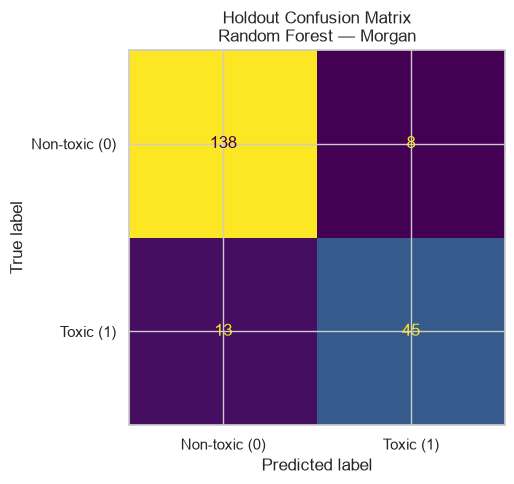

In [10]:
# IMPORTANT: candidate selection is based only on grouped CV within the training data.
best_cv_row = cv_results.iloc[0]
best_model_name = str(best_cv_row["model"])
best_feature_type = str(best_cv_row["features"])
best_estimator = fitted_models[best_model_name]
best_predictions = prediction_outputs[best_model_name]
best_y_pred = best_predictions["y_pred"]
best_y_score = best_predictions["y_score"]

print("Provisional candidate selected from training-only grouped CV:", best_model_name)
print("Feature representation:", best_feature_type)
print("Mean CV PR-AUC:", round(float(best_cv_row["cv_average_precision_mean"]), 4))
print("Holdout PR-AUC (reported after selection):", round(float(average_precision_score(y_test, best_y_score)), 4))
print("\nHoldout classification report:")
print(classification_report(y_test, best_y_pred, labels=[0, 1],
                            target_names=["Non-toxic (label 0)", "Toxic (label 1)"],
                            zero_division=0, digits=3))

cm = confusion_matrix(y_test, best_y_pred, labels=[0, 1])
display(pd.DataFrame(cm,
    index=["Actual non-toxic (0)", "Actual toxic (1)"],
    columns=["Predicted non-toxic (0)", "Predicted toxic (1)"]))

fig, ax = plt.subplots(figsize=(5.8, 5))
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Non-toxic (0)", "Toxic (1)"]).plot(
    ax=ax, colorbar=False, values_format="d"
)
ax.set_title(f"Holdout Confusion Matrix\n{best_model_name}")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "04_provisional_candidate_confusion_matrix.png", dpi=220, bbox_inches="tight")
plt.show()

## Cell 11 — Compare holdout metrics (do not use them for tuning)

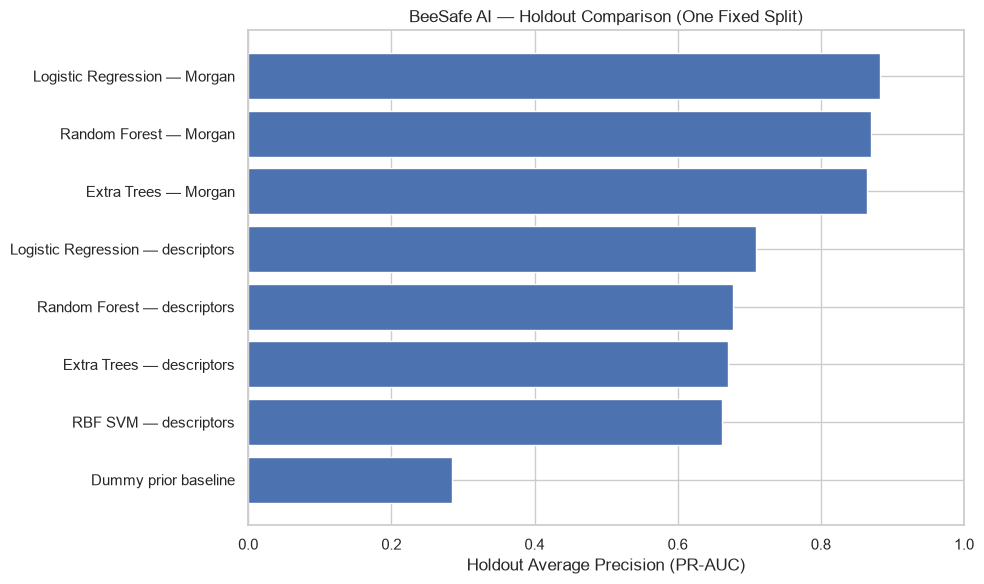

Interpret holdout results cautiously: a single holdout split has sampling uncertainty.
Do not repeatedly adjust model settings based on holdout performance.


In [11]:
# Holdout scores are reported for transparent diagnostics. Keep the model choice based on training CV.
plot_test = holdout_results.sort_values("test_average_precision", ascending=True)
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(plot_test["model"], plot_test["test_average_precision"])
ax.set_xlabel("Holdout Average Precision (PR-AUC)")
ax.set_title("BeeSafe AI — Holdout Comparison (One Fixed Split)")
ax.set_xlim(0, 1)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "04_holdout_model_comparison.png", dpi=220, bbox_inches="tight")
plt.show()

print("Interpret holdout results cautiously: a single holdout split has sampling uncertainty.")
print("Do not repeatedly adjust model settings based on holdout performance.")

## Cell 12 — Save predictions, split and model artifacts

In [12]:
# Save predictions for the provisional CV-selected candidate.
test_meta = metadata.iloc[test_idx].reset_index(drop=True)
prediction_table = test_meta[[c for c in ["source_row_index", "name", "CID", "CAS", "label", "structure_group"] if c in test_meta.columns]].copy()
prediction_table["y_true"] = y_test
prediction_table["y_pred"] = best_y_pred
prediction_table["score_for_toxic_class_1"] = best_y_score
prediction_table.to_csv(REPORT_DIR / "04_provisional_candidate_holdout_predictions.csv", index=False, encoding="utf-8-sig")

# Persist the selected estimator together with metadata needed to interpret its feature matrix.
bundle = {
    "model": best_estimator,
    "model_name": best_model_name,
    "feature_type": best_feature_type,
    "descriptor_names": descriptor_names,
    "target": "label",
    "positive_class": 1,
    "random_state": RANDOM_STATE,
    "selection_metric": "mean grouped-CV Average Precision (PR-AUC) on training split",
    "holdout_groups_disjoint": True,
}
model_path = MODEL_DIR / "04_provisional_best_baseline.joblib"
joblib.dump(bundle, model_path)

print("Saved holdout predictions:", REPORT_DIR / "04_provisional_candidate_holdout_predictions.csv")
print("Saved provisional model bundle:", model_path)
print("Note: this is a baseline candidate, not a final production model.")

Saved holdout predictions: E:\CODE\Python\ALL Project\Machine Learning\BeeSafe AI\reports\model_evaluation\04_provisional_candidate_holdout_predictions.csv
Saved provisional model bundle: E:\CODE\Python\ALL Project\Machine Learning\BeeSafe AI\models\04_provisional_best_baseline.joblib
Note: this is a baseline candidate, not a final production model.


## Cell 13 — Final checks and reproducibility summary

In [13]:
# Verify that the raw CSV was not touched by this notebook and that no structure group leaked.
RAW_PATH = PROJECT_ROOT / "data" / "raw" / "dataset_final.csv"
raw_hash_now = hashlib.sha256(RAW_PATH.read_bytes()).hexdigest() if RAW_PATH.exists() else None

assert len(train_idx) + len(test_idx) == len(y)
assert set(groups_train).isdisjoint(set(groups_test))
assert np.array_equal(y_train, y[train_idx])
assert np.array_equal(y_test, y[test_idx])

summary = {
    "project": "BeeSafe AI",
    "phase": "04_baseline_model_training_and_evaluation",
    "dataset_rows_used": int(len(y)),
    "train_rows": int(len(train_idx)),
    "holdout_rows": int(len(test_idx)),
    "train_unique_structure_groups": int(len(set(groups_train))),
    "holdout_unique_structure_groups": int(len(set(groups_test))),
    "train_test_group_overlap": int(len(set(groups_train) & set(groups_test))),
    "label_counts_all": {str(k): int(v) for k, v in pd.Series(y).value_counts().sort_index().items()},
    "label_counts_train": {str(k): int(v) for k, v in pd.Series(y_train).value_counts().sort_index().items()},
    "label_counts_holdout": {str(k): int(v) for k, v in pd.Series(y_test).value_counts().sort_index().items()},
    "model_candidates": list(models.keys()),
    "selection_metric": "mean grouped-CV Average Precision (PR-AUC) on training data",
    "provisional_candidate": best_model_name,
    "provisional_candidate_features": best_feature_type,
    "cv_mean_average_precision": float(best_cv_row["cv_average_precision_mean"]),
    "cv_std_average_precision": float(best_cv_row["cv_average_precision_std"]),
    "holdout_average_precision": float(average_precision_score(y_test, best_y_score)),
    "holdout_roc_auc": float(roc_auc_score(y_test, best_y_score)),
    "raw_sha256_matches_phase03": raw_hash_now == phase03_manifest.get("raw_data_sha256"),
    "raw_dataset_modified": False if raw_hash_now == phase03_manifest.get("raw_data_sha256") else None,
    "warning": "Exploratory baseline only. Do not interpret as field-level ecological risk or a regulatory safety determination.",
}
summary_path = REPORT_DIR / "04_baseline_training_summary.json"
with summary_path.open("w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2, ensure_ascii=False)

print("=" * 68)
print("BEESAFE AI — PHASE 04 BASELINE TRAINING COMPLETE")
print("=" * 68)
print("Baseline records:", len(y))
print("Train / holdout:", len(train_idx), "/", len(test_idx))
print("Train-test structure-group overlap:", summary["train_test_group_overlap"])
print("Provisional CV-selected candidate:", best_model_name)
print("Mean grouped CV PR-AUC:", round(summary["cv_mean_average_precision"], 4))
print("Holdout PR-AUC:", round(summary["holdout_average_precision"], 4))
print("Raw CSV hash matches Phase 03 manifest:", summary["raw_sha256_matches_phase03"])
print("Summary saved:", summary_path)
print("Next: Phase 05 — model selection, optimization and robust validation.")

display(cv_results[["model", "features", "cv_average_precision_mean", "cv_roc_auc_mean", "cv_f1_mean"]].round(4))

BEESAFE AI — PHASE 04 BASELINE TRAINING COMPLETE
Baseline records: 1025
Train / holdout: 821 / 204
Train-test structure-group overlap: 0
Provisional CV-selected candidate: Random Forest — Morgan
Mean grouped CV PR-AUC: 0.7593
Holdout PR-AUC: 0.8706
Raw CSV hash matches Phase 03 manifest: True
Summary saved: E:\CODE\Python\ALL Project\Machine Learning\BeeSafe AI\reports\model_evaluation\04_baseline_training_summary.json
Next: Phase 05 — model selection, optimization and robust validation.


,model,features,cv_average_precision_mean,cv_roc_auc_mean,cv_f1_mean
0,Random Forest — Morgan,morgan,0.7593,0.8237,0.6528
1,Extra Trees — Morgan,morgan,0.7533,0.8177,0.6648
2,Logistic Regression — Morgan,morgan,0.6937,0.7854,0.6118
3,Random Forest — descriptors,descriptors,0.5875,0.7241,0.4710
4,Extra Trees — descriptors,descriptors,0.5846,0.7233,0.4993
5,RBF SVM — descriptors,descriptors,0.5395,0.6892,0.4782
6,Logistic Regression — descriptors,descriptors,0.4740,0.6817,0.5085
7,Dummy prior baseline,descriptors,0.2874,0.5000,0.0000
